# Does what drives gaze change over the course of free viewing?
*An exploratory analysis of COCO-FreeView*

**Question.** In 5-second free viewing of natural scenes, are early fixations better explained by low-level
feature contrast, and later fixations by objects? This touches the idea that bottom-up saliency (for example,
the V1 saliency hypothesis, Li 2002) dominates fast, early orienting, while object- and meaning-level factors
take over with time.

**Approach.** For each fixation index *k* we score three maps at the fixated location (NSS):

| map | what it stands for |
|---|---|
| **center** | where people look on *any* image (empirical, built from the other half of images) |
| **contrast** | a simple low-level feature-contrast baseline: intensity, colour opponency, orientation |
| **objects** | COCO object masks |

and we measure how often fixation *k* lands on an annotated object.

**The control that matters.** Every number is shown next to a *shuffled* version: the same map scored at
fixations recorded on a *different* image. Natural images put objects and contrast near the middle, and people
look near the middle, so raw scores mix "image-specific guidance" with "center bias". Only the gap between
own and shuffled is evidence that the image itself guided gaze.

**Scope.** Exploratory. The contrast map is a transparent baseline, **not** a model of V1. Use train/validation
fixations only.

### Data you need (not included; the dataset terms forbid redistribution)
1. Fixations: `COCOFreeView_fixations_trainval.json` (COCO-FreeView page)
2. Stimuli: the COCO-Search18 TP and TA image sets (1680x1050), unzipped anywhere under `data/stimuli/`
3. Object annotations: COCO 2017 `instances_train2017.json` and `instances_val2017.json` in `data/annotations/`

See `README.md` for links.

## 0 · Setup

In [1]:
import glob, os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import fvtools as fv

DATA_DIR   = os.environ.get("FV_DATA_DIR", "data")
FIX_JSON   = os.path.join(DATA_DIR, "COCOFreeView_fixations_trainval.json")
STIM_DIR   = os.path.join(DATA_DIR, "stimuli")
ANN_FILES  = sorted(glob.glob(os.path.join(DATA_DIR, "annotations", "instances_*2017.json")))

N_IMAGES   = int(os.environ.get("FV_N_IMAGES", 800))  # start small; set to 0 for all images
DROP_FIRST = True     # fixation 0 is usually the central start dot (checked in section 1)
MAX_IDX    = 12       # analyse fixations 1..MAX_IDX (later indices have few scanpaths)
COMBINE    = "max"    # how contrast channels combine: "max" (V1SH-style) or "mean" (Itti-Koch-style)
PX_PER_DEG = None     # set from the dataset README/paper to report saccades in degrees
SEED       = 0
os.makedirs("figures", exist_ok=True); os.makedirs("cache", exist_ok=True)

# chart style: recessive axes, thin lines, fixed colour per map
C = {"objects": "#2a78d6", "contrast": "#eb6834", "center": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "lines.linewidth": 2, "legend.frameon": False,
})

def ci_line(ax, d, color, label, dashed=False, end_label=True):
    ls = "--" if dashed else "-"
    ax.plot(d.idx, d["mean"], ls, color=color, marker="o", ms=4, label=label)
    ax.fill_between(d.idx, d.lo, d.hi, color=color, alpha=0.15 if not dashed else 0.08, lw=0)
    if end_label:
        ax.annotate(label, (d.idx.iloc[-1], d["mean"].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK2, fontsize=9)
print("annotation files:", ANN_FILES)

annotation files: ['data/annotations/instances_train2017.json', 'data/annotations/instances_val2017.json']


## 1 · Load fixations and check the first fixation

In [2]:
raw = fv.load_fixations(FIX_JSON)
raw, frame = fv.to_stimulus_frame(raw)
raw = fv.add_saccades(raw, PX_PER_DEG)   # amplitudes computed before any fixation is dropped
lens = raw.groupby("scan").size()
print(f"coordinate frame detected: {frame}")
print(f"{raw.scan.nunique():,} scanpaths · {raw.image.nunique():,} images · "
      f"{raw.subject.nunique()} subjects · {len(raw):,} fixations")
print(f"fixations per scanpath: median {lens.median():.0f}, IQR {lens.quantile(.25):.0f}-{lens.quantile(.75):.0f}")
print("splits:", raw.split.value_counts(dropna=False).to_dict())

coordinate frame detected: 1680x1050
43,048 scanpaths · 4,317 images · 10 subjects · 665,005 fixations
fixations per scanpath: median 16, IQR 14-18
splits: {'train': 572184, 'valid': 92821}


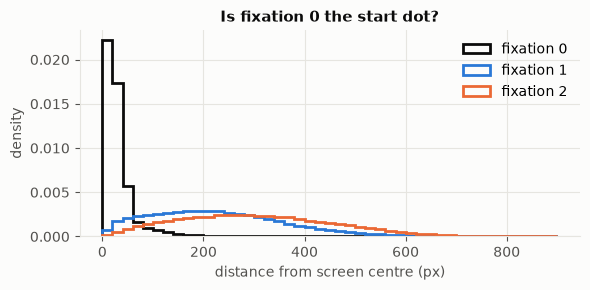

median distance from centre by index: {0: 22.0, 1: 215.0, 2: 295.0, 3: 311.0}


In [3]:
# Trials start with a central fixation dot. If fixation 0 sits on the screen centre, it reflects
# the task, not the image, and should be dropped.
dist = np.hypot(raw.x - fv.STIM_W / 2, raw.y - fv.STIM_H / 2)
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 900, 46)
for k, col in [(0, INK), (1, C["objects"]), (2, C["contrast"])]:
    ax.hist(dist[raw.idx == k], bins=bins, histtype="step", lw=2, color=col, density=True, label=f"fixation {k}")
ax.set(xlabel="distance from screen centre (px)", ylabel="density", title="Is fixation 0 the start dot?")
ax.legend(); plt.tight_layout(); plt.savefig("figures/00_first_fixation.png", dpi=160); plt.show()
print("median distance from centre by index:", dist.groupby(raw.idx).median().head(4).round(0).to_dict())

## 2 · Match images, annotations and stimuli

In [4]:
stim_index = fv.index_stimuli(STIM_DIR)
coco = fv.CocoIndex(ANN_FILES)
images = sorted(set(raw.image) & set(stim_index) & set(coco.by_name))
print(f"images with fixations: {raw.image.nunique():,} · with stimulus file: "
      f"{len(set(raw.image) & set(stim_index)):,} · usable (also annotated): {len(images):,}")

rng = np.random.default_rng(SEED)
if N_IMAGES and N_IMAGES < len(images):
    images = sorted(rng.choice(images, N_IMAGES, replace=False))

fix = raw[raw.image.isin(images)]
if DROP_FIRST:
    fix = fix[fix.idx >= 1]
by_image = dict(tuple(fix.groupby("image")))
cmaps = fv.center_maps(fix, images, seed=SEED)

# shuffled control: each image is scored at fixations from one other image (a derangement)
perm = list(rng.permutation(images))
donor = {perm[i]: perm[(i + 1) % len(perm)] for i in range(len(perm))}
print(f"analysing {len(images):,} images, {len(fix):,} fixations")

loading annotations into memory...
Done (t=46.17s)
creating index...
index created!
loading annotations into memory...
Done (t=0.69s)
creating index...
index created!
images with fixations: 4,317 · with stimulus file: 4,317 · usable (also annotated): 4,317
analysing 800 images, 115,517 fixations


## 3 · Score every fixation (cached)

In [5]:
cache = f"cache/scored_n{len(images)}_{COMBINE}_drop{int(DROP_FIRST)}_s{SEED}.pkl"
if os.path.exists(cache):
    own, shuf, info = pd.read_pickle(cache)
else:
    own_l, shuf_l, info_l, t0 = [], [], [], time.time()
    for i, name in enumerate(images):
        stim = np.asarray(Image.open(stim_index[name]).convert("RGB"))
        if stim.shape[:2] != (fv.STIM_H, fv.STIM_W):
            stim = np.asarray(Image.fromarray(stim).resize((fv.STIM_W, fv.STIM_H)))
        o, s, inf = fv.score_image(name, stim, coco, by_image[name], by_image[donor[name]],
                                   cmaps[name], combine=COMBINE)
        own_l.append(o); shuf_l.append(s); info_l.append(inf)
        if (i + 1) % 100 == 0:
            print(f"  {i + 1}/{len(images)} images · {time.time() - t0:.0f}s")
    own, shuf, info = pd.concat(own_l), pd.concat(shuf_l), pd.DataFrame(info_l)
    pd.to_pickle((own, shuf, info), cache)
own = own[own.idx <= MAX_IDX]; shuf = shuf[shuf.idx <= MAX_IDX]
print(f"{len(own):,} own fixations · {len(shuf):,} shuffled-control fixations")

  100/800 images · 31s
  200/800 images · 63s
  300/800 images · 93s
  400/800 images · 123s
  500/800 images · 154s
  600/800 images · 185s
  700/800 images · 216s
  800/800 images · 251s
92,190 own fixations · 91,938 shuffled-control fixations


### Sanity check: are the object masks aligned with the stimuli?
The papers say images were *resized and padded* to 1680x1050 but not exactly how, so the code tries three
placements per image and keeps the one matching the visible image area. Check the counts, then **look at the
overlays**: outlines should sit on the objects. If they don't, nothing downstream can be trusted.

{'fit_center': 800}
alignment IoU: median 0.999, images below 0.95: 6


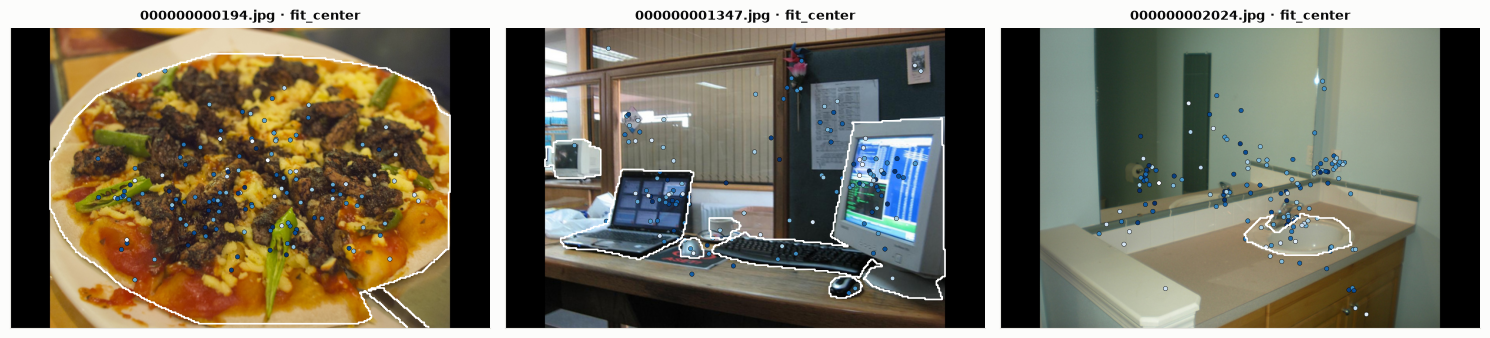

In [6]:
print(info["mode"].value_counts().to_dict())
print(f"alignment IoU: median {info.iou.median():.3f}, images below 0.95: {(info.iou < 0.95).sum()}")

ex = images[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, name in zip(axes, ex):
    stim = np.asarray(Image.open(stim_index[name]).convert("RGB"))
    _, _, inf = fv.score_image(name, stim, coco, by_image[name], by_image[donor[name]], cmaps[name],
                               combine=COMBINE, keep_maps=True)
    ax.imshow(stim); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    up = np.kron(inf["glab"] >= 0, np.ones((fv.GRID_DS, fv.GRID_DS)))
    ax.contour(up, levels=[0.5], colors="#ffffff", linewidths=1.2)
    f = by_image[name]
    ax.scatter(f.x, f.y, s=10, c=f.idx, cmap="Blues_r", edgecolors="#0b0b0b", linewidths=0.3)
    ax.set_title(f"{name} · {inf['mode']}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/01_alignment_check.png", dpi=140); plt.show()

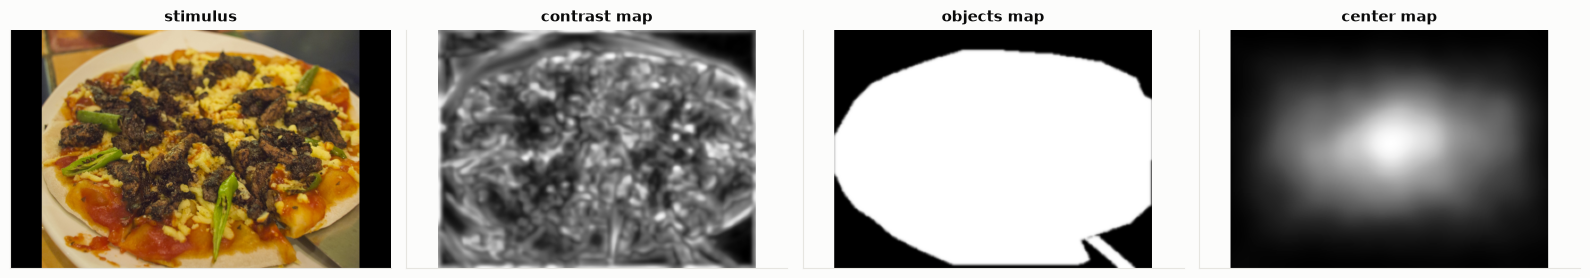

In [7]:
# What the three maps look like for one image (z-scored; padding blank)
name = ex[0]
stim = np.asarray(Image.open(stim_index[name]).convert("RGB"))
_, _, inf = fv.score_image(name, stim, coco, by_image[name], by_image[donor[name]], cmaps[name],
                           combine=COMBINE, keep_maps=True)
fig, axes = plt.subplots(1, 4, figsize=(16, 2.9))
axes[0].imshow(stim); axes[0].set_title("stimulus")
for ax, k in zip(axes[1:], ["contrast", "objects", "center"]):
    ax.imshow(inf["maps"][k], cmap="Greys_r"); ax.set_title(f"{k} map")
for ax in axes: ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig("figures/02_example_maps.png", dpi=140); plt.show()

## Analysis 1 · Do fixations land on objects, and does that change over time?
Three lines per index: share of fixations on any object (**own**), the same for fixations borrowed from another
image (**shuffled**), and the share of the image covered by objects (**area**, what uniformly random gaze would get).

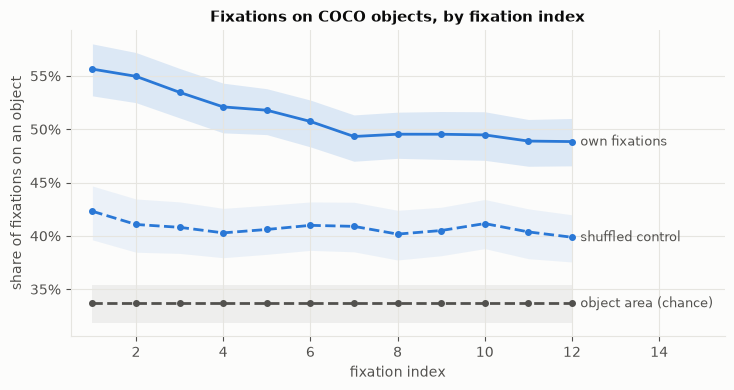

idx,1,2,3,4,5,6,7,8,9,10,11,12
own,0.556,0.550,0.535,0.521,0.518,0.507,0.493,0.495,0.495,0.495,0.489,0.488
shuffled,0.423,0.411,0.408,0.403,0.406,0.410,0.409,0.402,0.405,0.412,0.404,0.399
area,0.337,0.337,0.337,0.337,0.337,0.337,0.337,0.337,0.337,0.337,0.337,0.337


In [8]:
o = fv.bootstrap_by_index(own.assign(v=own.on_object.astype(float)), "v", MAX_IDX)
s = fv.bootstrap_by_index(shuf.assign(v=shuf.on_object.astype(float)), "v", MAX_IDX)
a = fv.bootstrap_by_index(own.assign(v=own.obj_area_frac), "v", MAX_IDX)

fig, ax = plt.subplots(figsize=(7.5, 4))
ci_line(ax, o, C["objects"], "own fixations")
ci_line(ax, s, C["objects"], "shuffled control", dashed=True)
ci_line(ax, a, INK2, "object area (chance)", dashed=True)
ax.set(xlabel="fixation index", ylabel="share of fixations on an object",
       title="Fixations on COCO objects, by fixation index", xlim=(0.5, MAX_IDX + 3.5))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig("figures/10_object_hits.png", dpi=160); plt.show()
display(pd.DataFrame({"idx": o.idx, "own": o["mean"].round(3), "shuffled": s["mean"].round(3),
                      "area": a["mean"].round(3)}).set_index("idx").T)

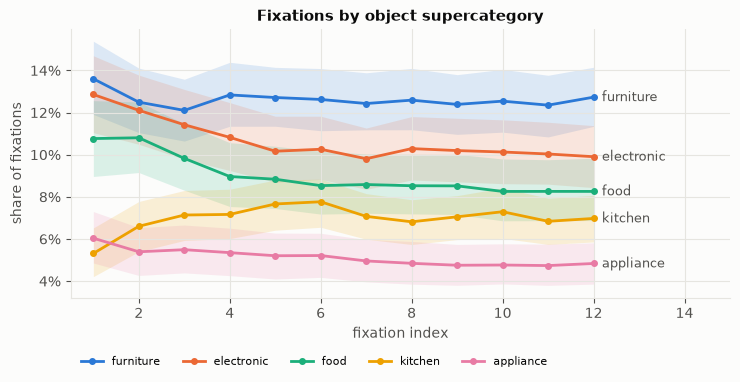

In [9]:
# Which kinds of objects? Share of fixations by COCO supercategory (top 5 overall).
top = own[own.on_object].supercat.value_counts().index[:5]
slots = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(7.5, 4))
for sc, col in zip(top, slots):
    d = fv.bootstrap_by_index(own.assign(v=(own.supercat == sc).astype(float)), "v", MAX_IDX)
    ci_line(ax, d, col, sc)
ax.set(xlabel="fixation index", ylabel="share of fixations", xlim=(0.5, MAX_IDX + 3),
       title="Fixations by object supercategory")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper left", ncol=5, fontsize=8, bbox_to_anchor=(0, -0.18))
plt.tight_layout(); plt.savefig("figures/11_supercategories.png", dpi=160); plt.show()

## Analysis 2 · Which map predicts fixation *k* best?
NSS = the z-scored map value at the fixated pixel (0 = chance, higher = better). Left: raw NSS for own fixations
(solid) and the shuffled control (dashed). Right: **own minus shuffled**, the image-specific part. The pattern
the question predicts is contrast relatively strong early and objects pulling ahead later, *on the right panel*.

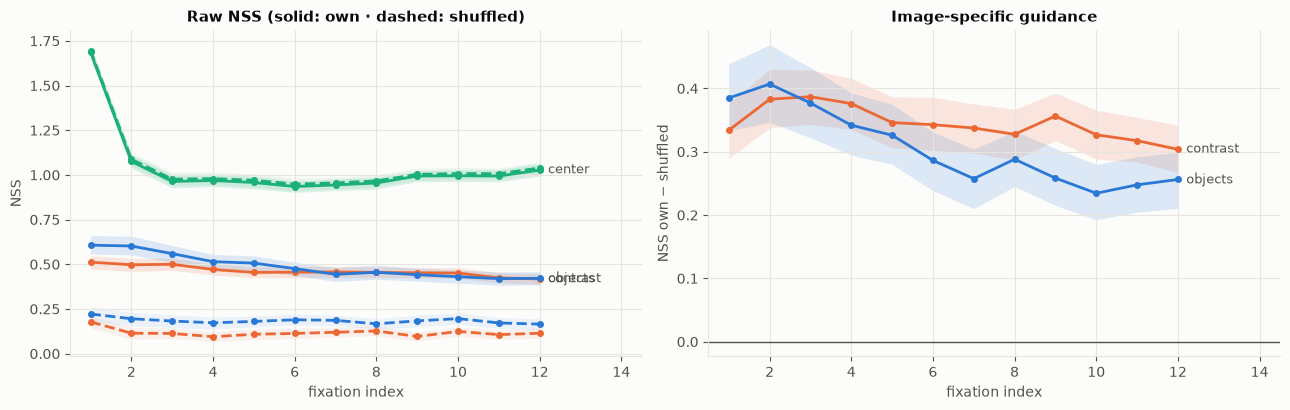

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for k in ["contrast", "objects", "center"]:
    d_own = fv.bootstrap_by_index(own, f"nss_{k}", MAX_IDX)
    d_sh = fv.bootstrap_by_index(shuf, f"nss_{k}", MAX_IDX)
    ci_line(ax1, d_own, C[k], k)
    ci_line(ax1, d_sh, C[k], k, dashed=True, end_label=False)
    if k == "center":
        continue  # the centre map is the same for every image, so own - shuffled is not meaningful
    # image-level difference, then bootstrap over images
    po = own.groupby(["map_image", "idx"])[f"nss_{k}"].mean()
    ps = shuf.groupby(["map_image", "idx"])[f"nss_{k}"].mean()
    diff = (po - ps).dropna().rename("v").reset_index()
    ci_line(ax2, fv.bootstrap_by_index(diff, "v", MAX_IDX), C[k], k)
ax1.set(xlabel="fixation index", ylabel="NSS", title="Raw NSS (solid: own · dashed: shuffled)",
        xlim=(0.5, MAX_IDX + 2.5))
ax2.axhline(0, color=INK2, lw=1)
ax2.set(xlabel="fixation index", ylabel="NSS own − shuffled", title="Image-specific guidance")
plt.tight_layout(); plt.savefig("figures/20_nss_by_index.png", dpi=160); plt.show()

## Analysis 3 · Saccade amplitude and fixation duration over time
A coarse look at whether viewing shifts from broad exploration (long saccades, short fixations) to local
inspection. With `PX_PER_DEG` set, amplitudes are in degrees of visual angle.

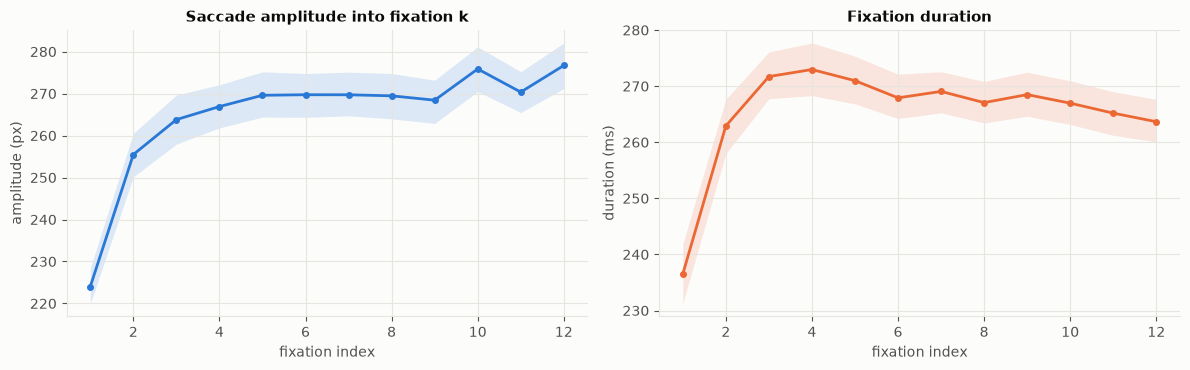

In [11]:
sac = raw[raw.image.isin(images) & (raw.idx >= 1) & (raw.idx <= MAX_IDX)].rename(columns={"image": "map_image"})
amp = "amp_deg" if PX_PER_DEG else "amp_px"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ci_line(ax1, fv.bootstrap_by_index(sac, amp, MAX_IDX), C["objects"], "", end_label=False)
ax1.set(xlabel="fixation index", ylabel=f"amplitude ({'deg' if PX_PER_DEG else 'px'})",
        title="Saccade amplitude into fixation k")
ci_line(ax2, fv.bootstrap_by_index(sac, "dur", MAX_IDX), C["contrast"], "", end_label=False)
ax2.set(xlabel="fixation index", ylabel="duration (ms)", title="Fixation duration")
plt.tight_layout(); plt.savefig("figures/30_saccades_durations.png", dpi=160); plt.show()

## Write-up notes
Fill these in from your own results before putting anything in an application.

**What I found** (one or two sentences per analysis, numbers with CIs):
- Analysis 1:
- Analysis 2:
- Analysis 3:

**Limitations to state honestly**
- The contrast map is a simple low-level baseline, not a model of V1 or of any specific theory.
- COCO masks cover labelled categories only; unlabelled objects (signs, text, parts) count as background.
- NSS by index mixes scanpaths of different lengths; late indices come from people who made more fixations.
- Object maps and contrast maps are correlated (objects are often high-contrast). A joint model, such as a
  logistic regression of "fixated vs. control location" on both maps per index, would separate them.

**Possible next steps**
- Fit that joint model per fixation index.
- Compare `COMBINE="max"` with `"mean"`: does max-over-features predict early fixations better?
- Check consistency across subjects (per-subject curves).
- Add a pretrained deep saliency model as a fourth map and ask *when* it beats the low-level baseline.